In [1]:
!pip install optuna

In [2]:
import tensorflow as tf
import numpy as np
import optuna
import os
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.applications import *
from sklearn.metrics import confusion_matrix, classification_report

2026-03-27 16:57:29.942052: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774630650.139863      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774630650.191350      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774630650.603435      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774630650.603476      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774630650.603479      55 computation_placer.cc:177] computation placer alr

In [3]:
DATA_DIR = "/kaggle/input/datasets/samerzaidan/split-data"

TRAIN_DIR = DATA_DIR + "/train"
VAL_DIR = DATA_DIR + "/val"
TEST_DIR = DATA_DIR + "/test"

In [4]:
ARCHITECTURES = [
    
    "EfficientNetB5",
    "EfficientNetB6",
    "EfficientNetB7",
    
    "EfficientNetV2S",
    "EfficientNetV2M",
    
    "ResNet50",
    "DenseNet121"
]

In [5]:
MODEL_RES = {

"EfficientNetB5":456,
"EfficientNetB6":528,
"EfficientNetB7":600,

"EfficientNetV2S":384,
"EfficientNetV2M":480,

"ResNet50":224,
"DenseNet121":224

}

In [7]:
def load_dataset(img_size,batch):

    train = tf.keras.preprocessing.image_dataset_from_directory(
        TRAIN_DIR,
        image_size=(img_size,img_size),
        batch_size=batch
    )

    val = tf.keras.preprocessing.image_dataset_from_directory(
        VAL_DIR,
        image_size=(img_size,img_size),
        batch_size=batch
    )

    test = tf.keras.preprocessing.image_dataset_from_directory(
        TEST_DIR,
        image_size=(img_size,img_size),
        batch_size=batch,
        shuffle=False
    )

    return train,val,test

In [8]:
def get_optimizer(name,lr):

    if name=="Adam":
        return tf.keras.optimizers.Adam(lr)

    if name=="AdamW":
        return tf.keras.optimizers.AdamW(lr)

    if name=="RMSprop":
        return tf.keras.optimizers.RMSprop(lr)

    if name=="SGD":
        return tf.keras.optimizers.SGD(lr,momentum=0.9)

In [9]:
def build_model(model_name, dropout, dense_units, img_size):

    inputs = tf.keras.Input(shape=(img_size, img_size, 3))

    data_augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.25),
        tf.keras.layers.RandomZoom(0.25),
        tf.keras.layers.RandomContrast(0.3),
        tf.keras.layers.RandomTranslation(0.2,0.2)
    ])

    x = data_augmentation(inputs)

    if model_name == "EfficientNetB5":
        base = EfficientNetB5(weights="imagenet", include_top=False)

    elif model_name == "EfficientNetB6":
        base = EfficientNetB6(weights="imagenet", include_top=False)

    elif model_name == "EfficientNetB7":
        base = EfficientNetB7(weights="imagenet", include_top=False)

    elif model_name == "EfficientNetV2S":
        base = EfficientNetV2S(weights="imagenet", include_top=False)

    elif model_name == "EfficientNetV2M":
        base = EfficientNetV2M(weights="imagenet", include_top=False)

    elif model_name == "ResNet50":
        base = ResNet50(weights="imagenet", include_top=False)

    elif model_name == "DenseNet121":
        base = DenseNet121(weights="imagenet", include_top=False)

    base.trainable = False

    x = base(x, training=False)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Dense(dense_units, activation="relu")(x)

    x = tf.keras.layers.Dropout(dropout)(x)

    outputs = tf.keras.layers.Dense(4, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)

    return model

In [10]:
def objective(trial):

    tf.keras.backend.clear_session()

    architecture = trial.suggest_categorical("architecture",ARCHITECTURES)

    batch_size = trial.suggest_categorical("batch_size",[8,16,32])

    lr = trial.suggest_float("lr",1e-5,1e-3,log=True)

    dropout = trial.suggest_float("dropout",0.2,0.5)

    dense_units = trial.suggest_categorical("dense_units",[128,256,512])

    optimizer_name = trial.suggest_categorical(
        "optimizer",
        ["Adam","AdamW","RMSprop","SGD"]
    )

    lr_factor = trial.suggest_float("lr_factor",0.1,0.5)

    lr_patience = trial.suggest_int("lr_patience",2,5)

    img_size = MODEL_RES[architecture]

    train,val,_ = load_dataset(img_size,batch_size)

    model = build_model(architecture,dropout,dense_units,img_size)

    optimizer = get_optimizer(optimizer_name,lr)

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=lr_factor,
        patience=lr_patience
    )

    history = model.fit(
        train,
        validation_data=val,
        epochs=8,
        callbacks=[reduce_lr],
        verbose=1
    )

    return max(history.history["val_accuracy"])

In [11]:
study = optuna.create_study(direction="maximize")

study.optimize(objective, n_trials=15, catch=(Exception,))

[I 2026-03-27 16:59:29,566] A new study created in memory with name: no-name-563428dc-7c61-427e-a16e-aaf34d586151


Found 4384 files belonging to 4 classes.
Found 548 files belonging to 4 classes.
Found 548 files belonging to 4 classes.
165234480/165234480 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/8


E0000 00:00:1774630806.779307      55 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb6_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1774630810.736477     159 cuda_dnn.cc:529] Loaded cuDNN version 91002


137/137 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.5803 - loss: 1.2904 - val_accuracy: 0.7701 - val_loss: 0.7541 - learning_rate: 3.7190e-04
Epoch 2/8
137/137 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.7616 - loss: 0.6951 - val_accuracy: 0.8522 - val_loss: 0.4766 - learning_rate: 3.7190e-04
Epoch 3/8
137/137 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.8123 - loss: 0.5336 - val_accuracy: 0.8193 - val_loss: 0.4635 - learning_rate: 3.7190e-04
Epoch 4/8
137/137 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.8087 - loss: 0.5630 - val_accuracy: 0.8321 - val_loss: 0.4086 - learning_rate: 3.7190e-04
Epoch 5/8
137/137 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.8324 - loss: 0.4685 - val_accuracy: 0.8321 - val_loss: 0.4896 - learning_rate: 3.7190e-04
Epoch 6/8
137/137 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.8469 - loss: 0.4103 - val_accuracy: 0.8704 - val_loss: 0.3514 - learning_rate: 3.7190e-04
Epoch 7/8
137/137 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.8597 - l

[I 2026-03-27 17:22:11,736] Trial 0 finished with value: 0.9233576655387878 and parameters: {'architecture': 'EfficientNetB6', 'batch_size': 32, 'lr': 0.0003718953099347851, 'dropout': 0.4276875429361001, 'dense_units': 512, 'optimizer': 'RMSprop', 'lr_factor': 0.11039484546262841, 'lr_patience': 2}. Best is trial 0 with value: 0.9233576655387878.


...

[I 2026-03-27 20:17:10,428] Trial 13 finished with value: 0.8083941340446472 and parameters: {'architecture': 'ResNet50', 'batch_size': 8, 'lr': 9.893397620548844e-05, 'dropout': 0.26222495687325675, 'dense_units': 512, 'optimizer': 'AdamW', 'lr_factor': 0.4179929612134507, 'lr_patience': 3}. Best is trial 10 with value: 0.9270073175430298.


Found 4384 files belonging to 4 classes.
Found 548 files belonging to 4 classes.
Found 548 files belonging to 4 classes.
Epoch 1/8


E0000 00:00:1774642661.663651      55 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb6_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


548/548 ━━━━━━━━━━━━━━━━━━━━ 212s 339ms/step - accuracy: 0.5452 - loss: 2.5132 - val_accuracy: 0.6807 - val_loss: 1.3528 - learning_rate: 9.4038e-04
Epoch 2/8
548/548 ━━━━━━━━━━━━━━━━━━━━ 179s 326ms/step - accuracy: 0.7031 - loss: 1.4482 - val_accuracy: 0.7646 - val_loss: 0.8293 - learning_rate: 9.4038e-04
Epoch 3/8
548/548 ━━━━━━━━━━━━━━━━━━━━ 179s 327ms/step - accuracy: 0.7454 - loss: 0.9464 - val_accuracy: 0.7883 - val_loss: 0.7835 - learning_rate: 9.4038e-04
Epoch 4/8
548/548 ━━━━━━━━━━━━━━━━━━━━ 179s 326ms/step - accuracy: 0.7803 - loss: 0.7610 - val_accuracy: 0.7774 - val_loss: 0.7936 - learning_rate: 9.4038e-04
Epoch 5/8
548/548 ━━━━━━━━━━━━━━━━━━━━ 179s 326ms/step - accuracy: 0.7964 - loss: 0.6703 - val_accuracy: 0.8029 - val_loss: 0.7978 - learning_rate: 9.4038e-04
Epoch 6/8
548/548 ━━━━━━━━━━━━━━━━━━━━ 179s 327ms/step - accuracy: 0.8358 - loss: 0.5065 - val_accuracy: 0.9252 - val_loss: 0.2487 - learning_rate: 2.6423e-04
Epoch 7/8
548/548 ━━━━━━━━━━━━━━━━━━━━ 179s 326ms/step -

[I 2026-03-27 20:41:41,337] Trial 14 finished with value: 0.9361313581466675 and parameters: {'architecture': 'EfficientNetB6', 'batch_size': 8, 'lr': 0.0009403808425231842, 'dropout': 0.2703349893709161, 'dense_units': 512, 'optimizer': 'RMSprop', 'lr_factor': 0.28097874122692534, 'lr_patience': 2}. Best is trial 14 with value: 0.9361313581466675.


In [ ]:
best = study.best_params
print(best)

In [1]:
import tensorflow as tf
import numpy as np
import optuna
import os
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.applications import *
from sklearn.metrics import confusion_matrix, classification_report

2026-03-27 21:31:16.722783: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774647076.915711      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774647076.968985      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774647077.394313      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774647077.394352      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774647077.394355      55 computation_placer.cc:177] computation placer alr

In [3]:
MODEL_RES = {

"EfficientNetB5":456,
"EfficientNetB6":528,
"EfficientNetB7":600,

"EfficientNetV2S":384,
"EfficientNetV2M":480,

"ResNet50":224,
"DenseNet121":224

}

In [5]:
DATA_DIR = "/kaggle/input/datasets/samerzaidan/split-data"

TRAIN_DIR = DATA_DIR + "/train"
VAL_DIR = DATA_DIR + "/val"
TEST_DIR = DATA_DIR + "/test"

In [6]:
def load_dataset(img_size,batch):

    train = tf.keras.preprocessing.image_dataset_from_directory(
        TRAIN_DIR,
        image_size=(img_size,img_size),
        batch_size=batch
    )

    val = tf.keras.preprocessing.image_dataset_from_directory(
        VAL_DIR,
        image_size=(img_size,img_size),
        batch_size=batch
    )

    test = tf.keras.preprocessing.image_dataset_from_directory(
        TEST_DIR,
        image_size=(img_size,img_size),
        batch_size=batch,
        shuffle=False
    )

    return train,val,test

In [8]:
def build_model(model_name, dropout, dense_units, img_size):

    inputs = tf.keras.Input(shape=(img_size, img_size, 3))

    data_augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.25),
        tf.keras.layers.RandomZoom(0.25),
        tf.keras.layers.RandomContrast(0.3),
        tf.keras.layers.RandomTranslation(0.2,0.2)
    ])

    x = data_augmentation(inputs)

    if model_name == "EfficientNetB5":
        base = EfficientNetB5(weights="imagenet", include_top=False)

    elif model_name == "EfficientNetB6":
        base = EfficientNetB6(weights="imagenet", include_top=False)

    elif model_name == "EfficientNetB7":
        base = EfficientNetB7(weights="imagenet", include_top=False)

    elif model_name == "EfficientNetV2S":
        base = EfficientNetV2S(weights="imagenet", include_top=False)

    elif model_name == "EfficientNetV2M":
        base = EfficientNetV2M(weights="imagenet", include_top=False)

    elif model_name == "ResNet50":
        base = ResNet50(weights="imagenet", include_top=False)

    elif model_name == "DenseNet121":
        base = DenseNet121(weights="imagenet", include_top=False)

    base.trainable = False

    x = base(x, training=False)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Dense(dense_units, activation="relu")(x)

    x = tf.keras.layers.Dropout(dropout)(x)

    outputs = tf.keras.layers.Dense(4, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)

    return model

In [10]:
def get_optimizer(name,lr):

    if name=="Adam":
        return tf.keras.optimizers.Adam(lr)

    if name=="AdamW":
        return tf.keras.optimizers.AdamW(lr)

    if name=="RMSprop":
        return tf.keras.optimizers.RMSprop(lr)

    if name=="SGD":
        return tf.keras.optimizers.SGD(lr,momentum=0.9)

In [11]:
best = {
'architecture': 'EfficientNetB6',
'batch_size': 8,
'lr': 0.0009403808425231842,
'dropout': 0.2703349893709161,
'dense_units': 512,
'optimizer': 'RMSprop',
'lr_factor': 0.28097874122692534,
'lr_patience': 2
}

arch = best["architecture"]

img_size = MODEL_RES[arch]

train,val,test = load_dataset(img_size,best["batch_size"])

model = build_model(
    arch,
    best["dropout"],
    best["dense_units"],
    img_size
)

optimizer = get_optimizer(best["optimizer"],best["lr"])

model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Found 4384 files belonging to 4 classes.
Found 548 files belonging to 4 classes.
Found 548 files belonging to 4 classes.


In [12]:
early_stop = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(

    monitor="val_loss",
    factor=best["lr_factor"],
    patience=best["lr_patience"],
    verbose=1
)

In [13]:
history = model.fit(

    train,
    validation_data=val,
    epochs=15,
    callbacks=[early_stop, reduce_lr]

)

Epoch 1/15


E0000 00:00:1774647377.100515      55 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_3_1/efficientnetb6_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1774647380.521700     151 cuda_dnn.cc:529] Loaded cuDNN version 91002


548/548 ━━━━━━━━━━━━━━━━━━━━ 215s 340ms/step - accuracy: 0.5681 - loss: 2.5050 - val_accuracy: 0.6825 - val_loss: 1.6241 - learning_rate: 9.4038e-04
Epoch 2/15
548/548 ━━━━━━━━━━━━━━━━━━━━ 178s 325ms/step - accuracy: 0.6954 - loss: 1.4493 - val_accuracy: 0.7245 - val_loss: 1.2726 - learning_rate: 9.4038e-04
Epoch 3/15
548/548 ━━━━━━━━━━━━━━━━━━━━ 178s 325ms/step - accuracy: 0.7248 - loss: 1.0759 - val_accuracy: 0.8303 - val_loss: 0.4870 - learning_rate: 9.4038e-04
Epoch 4/15
548/548 ━━━━━━━━━━━━━━━━━━━━ 178s 324ms/step - accuracy: 0.7653 - loss: 0.8426 - val_accuracy: 0.8467 - val_loss: 0.5183 - learning_rate: 9.4038e-04
Epoch 5/15
548/548 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step - accuracy: 0.7921 - loss: 0.7169
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.00026422702773360883.
548/548 ━━━━━━━━━━━━━━━━━━━━ 178s 324ms/step - accuracy: 0.7921 - loss: 0.7168 - val_accuracy: 0.7956 - val_loss: 0.7187 - learning_rate: 9.4038e-04
Epoch 6/15
548/548 ━━━━━━━━━━━━━━━━━━━━ 178s 325ms/step -

In [14]:
base_model = model.layers[2]

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(best["lr"] / 10),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_history = model.fit(
    train,
    validation_data=val,
    epochs=20,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/20


E0000 00:00:1774650258.090840      55 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_3_1/efficientnetb6_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


548/548 ━━━━━━━━━━━━━━━━━━━━ 229s 364ms/step - accuracy: 0.8461 - loss: 0.4723 - val_accuracy: 0.8650 - val_loss: 0.3735 - learning_rate: 9.4038e-05
Epoch 2/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 192s 351ms/step - accuracy: 0.8893 - loss: 0.3376 - val_accuracy: 0.9325 - val_loss: 0.1490 - learning_rate: 9.4038e-05
Epoch 3/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 192s 351ms/step - accuracy: 0.9080 - loss: 0.2641 - val_accuracy: 0.9526 - val_loss: 0.1286 - learning_rate: 9.4038e-05
Epoch 4/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 192s 350ms/step - accuracy: 0.9248 - loss: 0.2112 - val_accuracy: 0.9562 - val_loss: 0.1334 - learning_rate: 9.4038e-05
Epoch 5/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step - accuracy: 0.9322 - loss: 0.1938
Epoch 5: ReduceLROnPlateau reducing learning rate to 2.6422702773360884e-05.
548/548 ━━━━━━━━━━━━━━━━━━━━ 192s 350ms/step - accuracy: 0.9322 - loss: 0.1938 - val_accuracy: 0.9161 - val_loss: 0.2413 - learning_rate: 9.4038e-05
Epoch 6/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 192s 351ms/step -

In [15]:
test_loss, test_acc = model.evaluate(test)

print("Test Accuracy:", test_acc)
print("Test Loss:", test_loss)

69/69 ━━━━━━━━━━━━━━━━━━━━ 19s 274ms/step - accuracy: 0.9856 - loss: 0.0233
Test Accuracy: 0.9762773513793945
Test Loss: 0.044085804373025894


In [16]:
y_true = []
y_pred = []

for images, labels in test:

    preds = model.predict(images)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 329ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [17]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
import seaborn as sns

acc = accuracy_score(y_true,y_pred)
precision = precision_score(y_true,y_pred,average="weighted")
recall = recall_score(y_true,y_pred,average="weighted")
f1 = f1_score(y_true,y_pred,average="weighted")

print("Accuracy:",acc)
print("Precision:",precision)
print("Recall:",recall)
print("F1 Score:",f1)

Accuracy: 0.9762773722627737
Precision: 0.9766914744621252
Recall: 0.9762773722627737
F1 Score: 0.9762793556804472


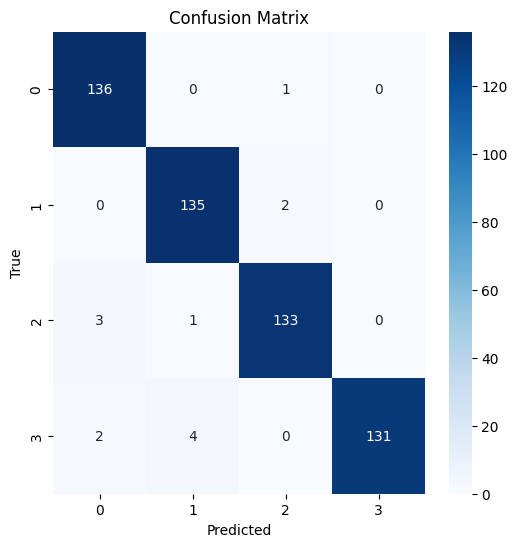

In [18]:
cm = confusion_matrix(y_true,y_pred)

plt.figure(figsize=(6,6))

sns.heatmap(
    cm,
    annot=True,
    cmap="Blues",
    fmt="d"
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.show()

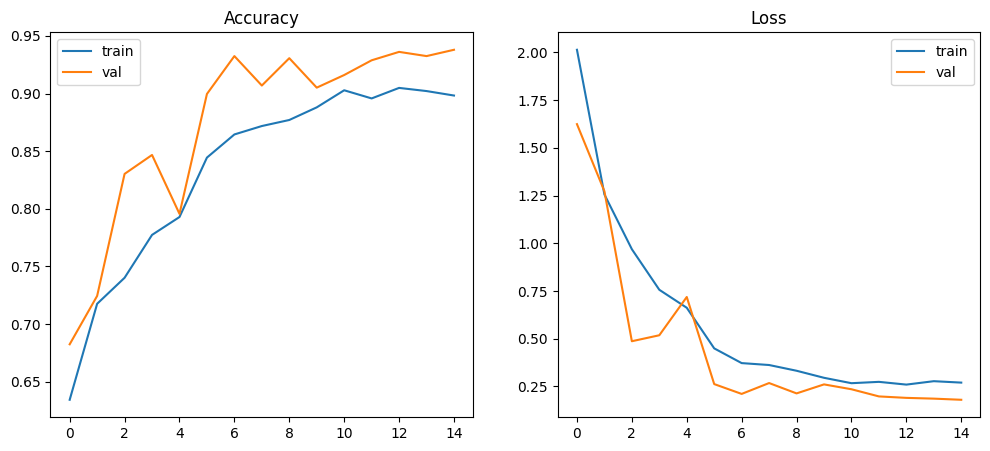

In [19]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(history.history["accuracy"],label="train")
plt.plot(history.history["val_accuracy"],label="val")

plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)

plt.plot(history.history["loss"],label="train")
plt.plot(history.history["val_loss"],label="val")

plt.title("Loss")
plt.legend()

plt.show()

In [20]:
model.save("model_traning_phase1.h5")

print("Model saved successfully")

Model saved successfully
